<a href="https://colab.research.google.com/github/MrTu286/TH-AI-Tuan3/blob/main/Tuan3_Ai.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [9]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, KFold, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import precision_score, recall_score, f1_score, make_scorer

from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.under_sampling import RandomUnderSampler
from imblearn.pipeline import Pipeline as ImbPipeline

RANDOM_STATE = 42

# 1. Nạp dữ liệu gốc Breast Cancer Wisconsin
cancer = load_breast_cancer(as_frame=True)
df_full = cancer.data.copy()
df_full["target"] = (cancer.target == 0).astype(int)

# 2. Tạo tập dữ liệu thực hành mất cân bằng (357 Benign + 60 Malignant)
benign_df = df_full[df_full["target"] == 0]
malignant_df = df_full[df_full["target"] == 1].sample(n=60, random_state=RANDOM_STATE)
df = pd.concat([benign_df, malignant_df], axis=0).sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True)

# 3. Chia Train / Test (80/20 có stratify)
X = df.drop(columns="target")
y = df["target"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

# 4. Khai báo bộ metric, chiến lược CV và hàm đánh giá
scoring = {
    "accuracy": "accuracy",
    "precision": make_scorer(precision_score, zero_division=0),
    "recall": make_scorer(recall_score, zero_division=0),
    "f1": make_scorer(f1_score, zero_division=0),
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision"
}

kfold = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
stratified_kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
skf = stratified_kfold

baseline_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=5000, random_state=RANDOM_STATE))
])

def cv_summary(model, X_data, y_data, cv):
    scores = cross_validate(model, X_data, y_data, cv=cv, scoring=scoring)
    row = {}
    for metric in scoring.keys():
        values = scores[f"test_{metric}"]
        row[f"{metric}_mean"] = values.mean()
        row[f"{metric}_std"] = values.std()
    return row

print("Khởi tạo môi trường và dữ liệu thành công!")

Khởi tạo môi trường và dữ liệu thành công!


In [10]:
imbalance_results = {}

configs = [
    ("40 mẫu malignant", 40),
    ("60 mẫu malignant (Gốc thực hành)", 60),
    ("120 mẫu malignant", 120),
    ("Toàn bộ dữ liệu gốc (212 mẫu)", None)
]

for label, n_mal in configs:
    benign_sub = df_full[df_full["target"] == 0]
    if n_mal is None:
        malignant_sub = df_full[df_full["target"] == 1]
    else:
        malignant_sub = df_full[df_full["target"] == 1].sample(n=n_mal, random_state=RANDOM_STATE)

    df_sub = pd.concat([benign_sub, malignant_sub], axis=0).sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True)
    X_sub = df_sub.drop(columns="target")
    y_sub = df_sub["target"]

    X_tr, _, y_tr, _ = train_test_split(
        X_sub, y_sub, test_size=0.20, random_state=RANDOM_STATE, stratify=y_sub
    )

    pipe = Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=5000, random_state=RANDOM_STATE))
    ])

    res = cv_summary(pipe, X_tr, y_tr, skf)
    res["Tỷ lệ Malignant (%)"] = round(y_sub.mean() * 100, 2)
    imbalance_results[label] = res

df_bai1 = pd.DataFrame(imbalance_results).T[
    ["Tỷ lệ Malignant (%)", "accuracy_mean", "recall_mean", "f1_mean", "pr_auc_mean"]
]
display(df_bai1.round(4))

,Tỷ lệ Malignant (%),accuracy_mean,recall_mean,f1_mean,pr_auc_mean
40 mẫu malignant,10.08,0.9938,0.9429,0.9692,0.9754
60 mẫu malignant (Gốc thực hành),14.39,0.9850,0.9400,0.9447,0.9855
120 mẫu malignant,25.16,0.9711,0.9274,0.9432,0.9882
Toàn bộ dữ liệu gốc (212 mẫu),37.26,0.9758,0.9529,0.9668,0.9939


In [11]:
cv_compare_bai2 = pd.DataFrame({
    "KFold (5 splits)": cv_summary(baseline_pipeline, X_train, y_train, kfold),
    "StratifiedKFold (5 splits)": cv_summary(baseline_pipeline, X_train, y_train, stratified_kfold)
}).T

display(cv_compare_bai2[
    ["accuracy_mean", "accuracy_std", "recall_mean", "recall_std", "f1_mean", "f1_std", "pr_auc_mean", "pr_auc_std"]
].round(4))

,accuracy_mean,accuracy_std,recall_mean,recall_std,f1_mean,f1_std,pr_auc_mean,pr_auc_std
KFold (5 splits),0.988,0.0112,0.9012,0.1052,0.9446,0.0613,0.9891,0.0188
StratifiedKFold (5 splits),0.985,0.0164,0.9400,0.1200,0.9447,0.0646,0.9855,0.0291


In [12]:
k_results = {}
for k in [3, 5, 10]:
    skf_k = StratifiedKFold(n_splits=k, shuffle=True, random_state=RANDOM_STATE)
    k_results[f"K = {k}"] = cv_summary(baseline_pipeline, X_train, y_train, skf_k)

df_bai3 = pd.DataFrame(k_results).T
display(df_bai3[
    ["accuracy_mean", "accuracy_std", "recall_mean", "recall_std", "f1_mean", "f1_std", "pr_auc_mean", "pr_auc_std"]
].round(4))

,accuracy_mean,accuracy_std,recall_mean,recall_std,f1_mean,f1_std,pr_auc_mean,pr_auc_std
K = 3,0.988,0.0042,0.9167,0.0295,0.9563,0.0162,0.9907,0.0132
K = 5,0.985,0.0164,0.9400,0.1200,0.9447,0.0646,0.9855,0.0291
K = 10,0.988,0.0147,0.9550,0.0907,0.9564,0.0550,0.9861,0.0417


In [13]:
ros_results = {}
for ratio in [0.5, 0.75, 1.0]:
    pipe_ros = ImbPipeline([
        ("scaler", StandardScaler()),
        ("sampler", RandomOverSampler(sampling_strategy=ratio, random_state=RANDOM_STATE)),
        ("model", LogisticRegression(max_iter=5000, random_state=RANDOM_STATE))
    ])
    ros_results[f"sampling_strategy = {ratio}"] = cv_summary(pipe_ros, X_train, y_train, skf)

df_bai4 = pd.DataFrame(ros_results).T
display(df_bai4[["accuracy_mean", "precision_mean", "recall_mean", "f1_mean", "pr_auc_mean"]].round(4))

,accuracy_mean,precision_mean,recall_mean,f1_mean,pr_auc_mean
sampling_strategy = 0.5,0.988,0.9618,0.96,0.9577,0.9836
sampling_strategy = 0.75,0.988,0.9618,0.96,0.9577,0.9855
sampling_strategy = 1.0,0.985,0.9418,0.96,0.9472,0.9855


In [14]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

classifiers = {
    "KNN": KNeighborsClassifier(),
    "SVM": SVC(probability=True, random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE)
}

clf_results = {}
for name, clf in classifiers.items():
    # Trường hợp 1: Không dùng StandardScaler
    pipe_no_scale = ImbPipeline([
        ("sampler", SMOTE(random_state=RANDOM_STATE)),
        ("model", clf)
    ])
    # Trường hợp 2: Có dùng StandardScaler
    pipe_scaled = ImbPipeline([
        ("scaler", StandardScaler()),
        ("sampler", SMOTE(random_state=RANDOM_STATE)),
        ("model", clf)
    ])

    clf_results[f"{name} (Không Scale)"] = cv_summary(pipe_no_scale, X_train, y_train, skf)
    clf_results[f"{name} (Có StandardScaler)"] = cv_summary(pipe_scaled, X_train, y_train, skf)

df_bai6 = pd.DataFrame(clf_results).T[
    ["accuracy_mean", "precision_mean", "recall_mean", "f1_mean", "roc_auc_mean", "pr_auc_mean"]
]
display(df_bai6.round(4))

,accuracy_mean,precision_mean,recall_mean,f1_mean,roc_auc_mean,pr_auc_mean
KNN (Không Scale),0.9429,0.7607,0.8978,0.8191,0.9369,0.8588
KNN (Có StandardScaler),0.9730,0.8833,0.9600,0.9128,0.9774,0.9442
SVM (Không Scale),0.9609,0.9124,0.8111,0.8544,0.9722,0.9159
SVM (Có StandardScaler),0.9880,0.9618,0.9600,0.9577,0.9919,0.9807
Decision Tree (Không Scale),0.9460,0.8034,0.8556,0.8165,0.9085,0.7184
Decision Tree (Có StandardScaler),0.9730,0.8975,0.9400,0.9117,0.9595,0.8484


Kích thước dữ liệu: (6497, 13)
Số giá trị thiếu: 0
Số dòng trùng lặp: 1177


,Số mẫu,Tỷ lệ (%)
Normal (<7) (0),5220,80.34
High Quality (>=7) (1),1277,19.66


,mean,std,min,max
total sulfur dioxide,115.7446,56.5219,6.00,440.00
free sulfur dioxide,30.5253,17.7494,1.00,289.00
residual sugar,5.4432,4.7578,0.60,65.80
fixed acidity,7.2153,1.2964,3.80,15.90
alcohol,10.4918,1.1927,8.00,14.90
type,0.2461,0.4308,0.00,1.00
volatile acidity,0.3397,0.1646,0.08,1.58
pH,3.2185,0.1608,2.72,4.01
sulphates,0.5313,0.1488,0.22,2.00
citric acid,0.3186,0.1453,0.00,1.66


Train shape: (5197, 12) | Test shape: (1300, 12)


,accuracy_mean,precision_mean,recall_mean,f1_mean,roc_auc_mean,pr_auc_mean
model,,,,,,
Random Forest - SMOTE,0.8649,0.6435,0.7003,0.6706,0.9120,0.7621
Random Forest - No Sampling,0.8826,0.7981,0.5387,0.6425,0.9129,0.7701
LogReg - Random UnderSampling,0.7220,0.3940,0.7727,0.5215,0.8100,0.4849
LogReg - Random OverSampling,0.7231,0.3934,0.7571,0.5174,0.8109,0.4879
LogReg - SMOTE,0.7225,0.3923,0.7531,0.5155,0.8104,0.4846
LogReg - No Sampling,0.8160,0.5712,0.2674,0.3630,0.8112,0.4966
Dummy (Most Frequent),0.8035,0.0000,0.0000,0.0000,0.5000,0.1965



>>> Pipeline được chọn theo f1_mean: Random Forest - SMOTE


,Test Score
Accuracy,0.8754
Precision,0.6794
Recall,0.6953
F1,0.6873
ROC-AUC,0.9189
PR-AUC,0.7866



Classification Report trên tập Test:
                        precision    recall  f1-score   support

       Normal (<7) (0)     0.9249    0.9195    0.9222      1044
High Quality (>=7) (1)     0.6794    0.6953    0.6873       256

              accuracy                         0.8754      1300
             macro avg     0.8021    0.8074    0.8047      1300
          weighted avg     0.8765    0.8754    0.8759      1300



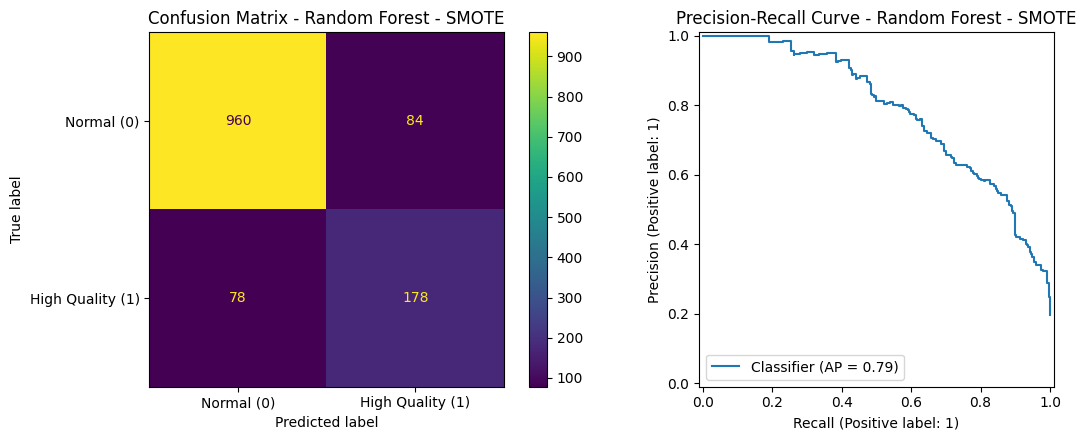

In [15]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
    make_scorer
)

from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.under_sampling import RandomUnderSampler
from imblearn.pipeline import Pipeline as ImbPipeline

RANDOM_STATE = 42

df = pd.read_csv("wine_quality_merged.csv")
print("Kích thước dữ liệu:", df.shape)
print("Số giá trị thiếu:", df.isna().sum().sum())
print("Số dòng trùng lặp:", df.duplicated().sum())

# Mã hóa biến phân loại 'type' (red=1, white=0) và tạo nhãn nhị phân (quality >= 7 -> 1)
df["type"] = (df["type"] == "red").astype(int)
df["target"] = (df["quality"] >= 7).astype(int)

# Kiểm tra phân bố lớp
class_count = df["target"].value_counts().sort_index()
class_percent = df["target"].value_counts(normalize=True).sort_index() * 100
class_dist = pd.DataFrame({"Số mẫu": class_count, "Tỷ lệ (%)": class_percent.round(2)})
class_dist.index = ["Normal (<7) (0)", "High Quality (>=7) (1)"]
display(class_dist)

# Kiểm tra thang đo feature
feature_cols = [c for c in df.columns if c not in ["quality", "target"]]
feature_scale = pd.DataFrame({
    "mean": df[feature_cols].mean(),
    "std": df[feature_cols].std(),
    "min": df[feature_cols].min(),
    "max": df[feature_cols].max()
}).sort_values("std", ascending=False)
display(feature_scale.head(10).round(4))

X = df[feature_cols]
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print(f"Train shape: {X_train.shape} | Test shape: {X_test.shape}")

scoring = {
    "accuracy": "accuracy",
    "precision": make_scorer(precision_score, zero_division=0),
    "recall": make_scorer(recall_score, zero_division=0),
    "f1": make_scorer(f1_score, zero_division=0),
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision"
}

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def cv_summary(model, X_data, y_data, cv):
    scores = cross_validate(model, X_data, y_data, cv=cv, scoring=scoring)
    row = {}
    for metric in scoring.keys():
        vals = scores[f"test_{metric}"]
        row[f"{metric}_mean"] = vals.mean()
        row[f"{metric}_std"] = vals.std()
    return row

models = {
    "Dummy (Most Frequent)": DummyClassifier(strategy="most_frequent"),

    "LogReg - No Sampling": ImbPipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=5000, random_state=RANDOM_STATE))
    ]),

    "LogReg - Random OverSampling": ImbPipeline([
        ("scaler", StandardScaler()),
        ("sampler", RandomOverSampler(random_state=RANDOM_STATE)),
        ("model", LogisticRegression(max_iter=5000, random_state=RANDOM_STATE))
    ]),

    "LogReg - Random UnderSampling": ImbPipeline([
        ("scaler", StandardScaler()),
        ("sampler", RandomUnderSampler(random_state=RANDOM_STATE)),
        ("model", LogisticRegression(max_iter=5000, random_state=RANDOM_STATE))
    ]),

    "LogReg - SMOTE": ImbPipeline([
        ("scaler", StandardScaler()),
        ("sampler", SMOTE(random_state=RANDOM_STATE)),
        ("model", LogisticRegression(max_iter=5000, random_state=RANDOM_STATE))
    ]),

    "Random Forest - No Sampling": ImbPipeline([
        ("scaler", StandardScaler()),
        ("model", RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE))
    ]),

    "Random Forest - SMOTE": ImbPipeline([
        ("scaler", StandardScaler()),
        ("sampler", SMOTE(random_state=RANDOM_STATE)),
        ("model", RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE))
    ])
}

all_results = []
for name, model in models.items():
    res = cv_summary(model, X_train, y_train, skf)
    res["model"] = name
    all_results.append(res)

cv_comparison = pd.DataFrame(all_results).set_index("model")
comparison_short = cv_comparison[
    ["accuracy_mean", "precision_mean", "recall_mean", "f1_mean", "roc_auc_mean", "pr_auc_mean"]
]
display(comparison_short.sort_values("f1_mean", ascending=False).round(4))

selection_metric = "f1_mean"
best_name = cv_comparison[selection_metric].idxmax()
best_model = models[best_name]

print(f"\n>>> Pipeline được chọn theo {selection_metric}: {best_name}")
best_model.fit(X_train, y_train)

y_pred = best_model.predict(X_test)
y_prob = best_model.predict_proba(X_test)[:, 1]

test_metrics = pd.Series({
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall": recall_score(y_test, y_pred, zero_division=0),
    "F1": f1_score(y_test, y_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, y_prob),
    "PR-AUC": average_precision_score(y_test, y_prob)
}, name="Test Score")
display(test_metrics.round(4))

print("\nClassification Report trên tập Test:")
print(classification_report(
    y_test, y_pred,
    target_names=["Normal (<7) (0)", "High Quality (>=7) (1)"],
    digits=4, zero_division=0
))

# Trực quan hóa Confusion Matrix và Precision-Recall Curve
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=["Normal (0)", "High Quality (1)"],
    ax=axes[0]
)
axes[0].set_title(f"Confusion Matrix - {best_name}")

PrecisionRecallDisplay.from_predictions(y_test, y_prob, ax=axes[1])
axes[1].set_title(f"Precision-Recall Curve - {best_name}")
plt.tight_layout()
plt.show()